# 🦠 FloodShield AI — Model 2: Disease Outbreak Prediction
**Algorithm:** XGBoost / CatBoost / Random Forest (comparison)
**Input:** Rainfall, Temperature, River Level, Flood Depth (Flood Risk indicators), Historical Disease Cases
**Output:** Disease Outbreak Risk (Medium / High / Critical)

### কীভাবে চালাবে:
1. Google Drive-এ `FloodShieldAI/data/` folder-এ `disease_prediction_dataset_fixed.xlsx` upload করো
2. এই notebook Colab-এ Upload করো
3. Runtime → Run all

### ⚠️ গুরুত্বপূর্ণ নোট (Data Leakage সতর্কতা)
`future_cases` কলাম দিয়েই `outbreak_risk` label তৈরি হয়েছে (threshold-based) — তাই **`future_cases` কে input feature হিসেবে ব্যবহার করা হয়নি**, এটা leakage হতো। শুধু `previous_week_cases` ও `previous_two_week_cases` (প্রকৃত historical data) ব্যবহার করা হয়েছে।

এছাড়া `outbreak_risk`-এর "Low" class-এ মাত্র ৬টা sample ছিল (30,000-এর মধ্যে) — এটা কার্যত unlearnable, তাই Low-কে Medium-এর সাথে merge করে 3-class (Medium/High/Critical) বানানো হয়েছে।


## 1️⃣ Setup: Install libraries + Mount Google Drive

In [1]:
!pip install xgboost lightgbm catboost scikit-learn pandas openpyxl -q

from google.colab import drive
drive.mount('/content/drive')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.4 MB/s eta 0:00:00
Mounted at /content/drive


## 2️⃣ Load Dataset
⚠️ path বদলে নাও তোমার Drive অনুযায়ী।


In [2]:
import pandas as pd
import numpy as np

DATA_PATH = '/content/drive/MyDrive/FloodShieldAI/data/disease_prediction_dataset_fixed.xlsx'  # <-- path বদলাও

df = pd.read_excel(DATA_PATH)
print("Shape:", df.shape)
df.head()


Shape: (30000, 24)


,date,district,upazila,season,rainfall_mm,temperature_c,humidity_percent,river_level_m,flood_depth_cm,population_density,...,future_cases,outbreak_risk,cholera_cases,diarrhea_cases,typhoid_cases,dengue_cases,hepatitis_a_cases,skin_disease_cases,dominant_disease,age_group_affected
0,2024-07-14,Munshiganj,Gazaria,Monsoon,116.1,34.7,90.3,4.80,38.5,4415,...,756,Critical,300,249,66,53,51,37,Cholera,Children
1,2025-02-19,Bagerhat,Fakirhat,Winter,4.7,22.1,59.6,2.50,2.4,4174,...,605,High,18,156,177,57,77,120,Typhoid,Children
2,2024-03-21,Sirajganj,Belkuchi,Summer,8.1,29.6,72.7,2.30,18.0,4720,...,543,High,73,139,179,26,60,65,Typhoid,Elderly
3,2022-06-29,Bhola,Daulatkhan,Monsoon,283.0,30.9,80.9,7.26,54.0,1971,...,944,Critical,170,387,132,75,99,80,Diarrhea,Adults
4,2023-03-20,Faridpur,Nagarkanda,Summer,23.7,33.6,80.2,1.95,23.8,3836,...,633,High,73,104,166,61,90,139,Typhoid,Children


## 3️⃣ Exploratory Check

In [3]:
print(df['outbreak_risk'].value_counts())
print()
print(df.isnull().sum().sum(), "total nulls")
df.describe()


outbreak_risk
High        19288
Critical     5918
Medium       4788
Low             6
Name: count, dtype: int64

0 total nulls


,rainfall_mm,temperature_c,humidity_percent,river_level_m,flood_depth_cm,population_density,sanitation_score,water_quality_index,previous_week_cases,previous_two_week_cases,future_cases,cholera_cases,diarrhea_cases,typhoid_cases,dengue_cases,hepatitis_a_cases,skin_disease_cases
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,82.793937,29.734193,75.041783,3.498303,21.881270,2657.98720,0.575461,78.574222,158.559967,148.464667,539.559333,110.299800,133.542233,86.825400,62.047033,75.149067,71.696700
std,93.574846,5.104950,12.625086,1.724674,17.520666,1345.24635,0.245357,10.397609,48.058459,48.476154,186.918157,83.726525,83.099314,41.230074,50.645192,38.699223,34.037464
min,0.000000,15.000000,41.300000,1.500000,0.000000,350.00000,0.150000,40.800000,22.000000,11.000000,101.000000,4.000000,10.000000,8.000000,1.000000,4.000000,3.000000
25%,11.800000,26.200000,64.800000,2.240000,8.300000,1491.00000,0.370000,71.100000,124.000000,113.000000,399.000000,47.000000,72.000000,56.000000,24.000000,47.000000,47.000000
50%,35.700000,30.900000,73.600000,2.760000,18.200000,2646.00000,0.580000,78.600000,156.000000,146.000000,517.000000,82.000000,111.000000,80.000000,46.000000,68.000000,66.000000
75%,144.000000,33.700000,87.300000,4.600000,32.100000,3827.00000,0.790000,86.400000,191.000000,181.000000,656.000000,155.000000,175.000000,110.000000,85.000000,96.000000,91.000000
max,662.600000,39.000000,100.000000,10.910000,101.100000,5000.00000,1.000000,100.000000,330.000000,322.000000,1200.000000,645.000000,684.000000,319.000000,457.000000,388.000000,288.000000


## 4️⃣ Fix Extreme Class Imbalance (Low → Medium merge)
"Low" class-এ মাত্র ৬টা sample, তাই একে Medium-এর সাথে merge করছি (bin narrow করা, 3-class বানানো)।


In [4]:
df['outbreak_risk_merged'] = df['outbreak_risk'].replace({'Low': 'Medium'})
print(df['outbreak_risk_merged'].value_counts())


outbreak_risk_merged
High        19288
Critical     5918
Medium       4794
Name: count, dtype: int64


## 5️⃣ Feature Engineering
**Input features (Leakage-free):** rainfall, temperature, humidity, river_level, flood_depth (flood risk indicators),
population_density, sanitation_score, water_quality_index, previous_week_cases, previous_two_week_cases, season

⚠️ `future_cases` বাদ দেওয়া হয়েছে (এটা দিয়েই target বানানো হয়েছিল, leakage হতো)


In [5]:
from sklearn.preprocessing import LabelEncoder

season_dummies = pd.get_dummies(df['season'], prefix='season')

feature_cols_base = ['rainfall_mm', 'temperature_c', 'humidity_percent', 'river_level_m',
                      'flood_depth_cm', 'population_density', 'sanitation_score',
                      'water_quality_index', 'previous_week_cases', 'previous_two_week_cases']

X = pd.concat([df[feature_cols_base], season_dummies], axis=1)
feature_cols = X.columns.tolist()

le = LabelEncoder()
y = le.fit_transform(df['outbreak_risk_merged'])
print("Label mapping:", dict(zip(le.classes_, le.transform(le.classes_))))
print("Features:", feature_cols)


Label mapping: {'Critical': np.int64(0), 'High': np.int64(1), 'Medium': np.int64(2)}
Features: ['rainfall_mm', 'temperature_c', 'humidity_percent', 'river_level_m', 'flood_depth_cm', 'population_density', 'sanitation_score', 'water_quality_index', 'previous_week_cases', 'previous_two_week_cases', 'season_Monsoon', 'season_Post-Monsoon', 'season_Summer', 'season_Winter']


## 6️⃣ Train/Test Split

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (24000, 14) Test: (6000, 14)


## 7️⃣ Train & Tune Models (XGBoost, CatBoost, Random Forest)

In [7]:
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score
import time

models_params = {
    'RandomForest': (
        RandomForestClassifier(random_state=42, class_weight='balanced'),
        {'n_estimators':[200,300,400], 'max_depth':[8,12,16,None], 'min_samples_leaf':[1,2,4]}
    ),
    'XGBoost': (
        XGBClassifier(random_state=42, eval_metric='mlogloss'),
        {'n_estimators':[150,250,350], 'max_depth':[4,6,8], 'learning_rate':[0.05,0.1,0.2]}
    ),
    'CatBoost': (
        CatBoostClassifier(random_state=42, verbose=0),
        {'iterations':[150,250,350], 'depth':[4,6,8], 'learning_rate':[0.05,0.1,0.2]}
    )
}

results = {}
trained_models = {}

for name, (model, params) in models_params.items():
    start = time.time()
    search = RandomizedSearchCV(model, params, n_iter=6, cv=3, scoring='f1_macro', random_state=42, n_jobs=-1)
    search.fit(X_train, y_train)
    best = search.best_estimator_
    preds = best.predict(X_test)
    acc = accuracy_score(y_test, preds)
    f1_macro = f1_score(y_test, preds, average='macro')
    elapsed = time.time() - start
    results[name] = f1_macro
    trained_models[name] = best
    print(f"{name}: Accuracy={acc:.4f} | Macro-F1={f1_macro:.4f} | Best params={search.best_params_} | Time={elapsed:.1f}s")

best_model_name = max(results, key=results.get)
best_model = trained_models[best_model_name]
print(f"\n🏆 Best model (by Macro-F1): {best_model_name} ({results[best_model_name]:.4f})")


RandomForest: Accuracy=0.9165 | Macro-F1=0.8986 | Best params={'n_estimators': 300, 'min_samples_leaf': 2, 'max_depth': None} | Time=184.5s
XGBoost: Accuracy=0.9133 | Macro-F1=0.8924 | Best params={'n_estimators': 150, 'max_depth': 4, 'learning_rate': 0.05} | Time=39.9s
CatBoost: Accuracy=0.9165 | Macro-F1=0.8970 | Best params={'learning_rate': 0.2, 'iterations': 150, 'depth': 6} | Time=74.2s

🏆 Best model (by Macro-F1): RandomForest (0.8986)


## 8️⃣ Detailed Evaluation

              precision    recall  f1-score   support

    Critical       0.90      0.93      0.92      1184
        High       0.94      0.93      0.93      3857
      Medium       0.84      0.85      0.84       959

    accuracy                           0.92      6000
   macro avg       0.89      0.90      0.90      6000
weighted avg       0.92      0.92      0.92      6000



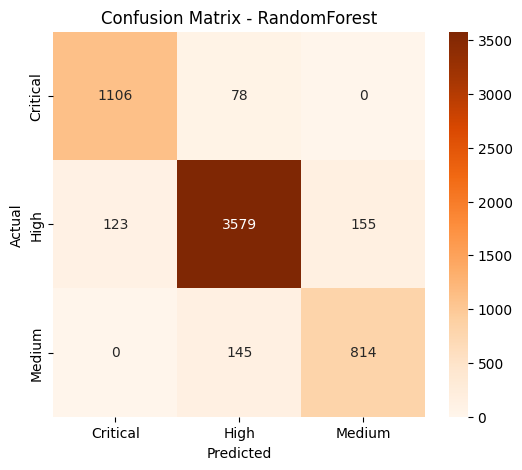

In [8]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

preds = best_model.predict(X_test)
print(classification_report(y_test, preds, target_names=le.classes_))

cm = confusion_matrix(y_test, preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.show()


## 9️⃣ Feature Importance

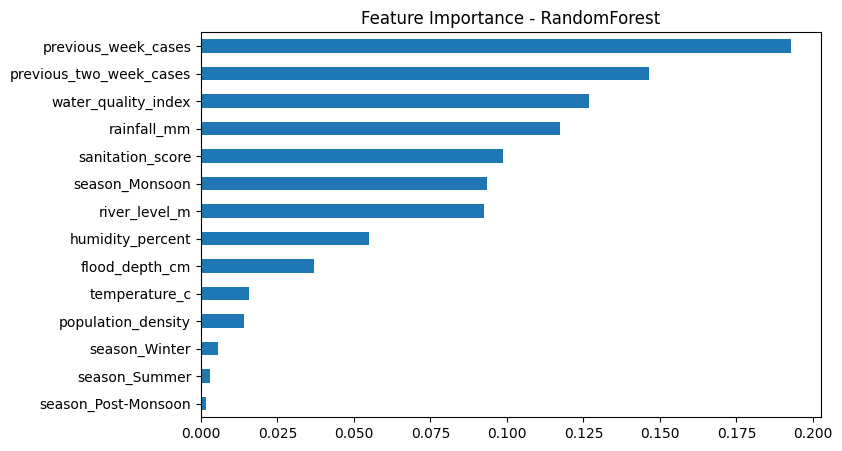

previous_week_cases        0.193000
previous_two_week_cases    0.146486
water_quality_index        0.126717
rainfall_mm                0.117214
sanitation_score           0.098581
season_Monsoon             0.093328
river_level_m              0.092555
humidity_percent           0.055082
flood_depth_cm             0.037094
temperature_c              0.015760
population_density         0.014144
season_Winter              0.005526
season_Summer              0.002927
season_Post-Monsoon        0.001586
dtype: float64


In [9]:
importances = best_model.feature_importances_
feat_imp = pd.Series(importances, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(8,5))
feat_imp.plot(kind='barh')
plt.title(f'Feature Importance - {best_model_name}')
plt.gca().invert_yaxis()
plt.show()
print(feat_imp)


## 🔟 Disease Outbreak Prediction Function

In [10]:
def predict_outbreak(rainfall_mm, temperature_c, humidity_percent, river_level_m, flood_depth_cm,
                      population_density, sanitation_score, water_quality_index,
                      previous_week_cases, previous_two_week_cases, season='Monsoon'):
    input_dict = {
        'rainfall_mm': rainfall_mm, 'temperature_c': temperature_c,
        'humidity_percent': humidity_percent, 'river_level_m': river_level_m,
        'flood_depth_cm': flood_depth_cm, 'population_density': population_density,
        'sanitation_score': sanitation_score, 'water_quality_index': water_quality_index,
        'previous_week_cases': previous_week_cases, 'previous_two_week_cases': previous_two_week_cases
    }
    season_cols = [c for c in feature_cols if c.startswith('season_')]
    for col in season_cols:
        season_name = col.replace('season_', '')
        input_dict[col] = 1 if season_name == season else 0

    input_df = pd.DataFrame([input_dict])[feature_cols]
    probs = best_model.predict_proba(input_df)[0]
    pred_class = le.classes_[probs.argmax()]
    prob_dict = dict(zip(le.classes_, probs.round(4)))
    return {
        'predicted_outbreak_risk': pred_class,
        'risk_probability_by_class': prob_dict
    }

# Example test
print(predict_outbreak(rainfall_mm=200, temperature_c=30, humidity_percent=85, river_level_m=7,
                        flood_depth_cm=50, population_density=2000, sanitation_score=0.4,
                        water_quality_index=55, previous_week_cases=180, previous_two_week_cases=160,
                        season='Monsoon'))


{'predicted_outbreak_risk': 'Critical', 'risk_probability_by_class': {'Critical': np.float64(0.8583), 'High': np.float64(0.1417), 'Medium': np.float64(0.0)}}


## 1️⃣1️⃣ Save Model

In [11]:
import joblib
import os

SAVE_DIR = '/content/drive/MyDrive/FloodShieldAI/models'
os.makedirs(SAVE_DIR, exist_ok=True)

joblib.dump(best_model, f'{SAVE_DIR}/disease_outbreak_model.pkl')
joblib.dump(le, f'{SAVE_DIR}/outbreak_risk_label_encoder.pkl')
joblib.dump(feature_cols, f'{SAVE_DIR}/outbreak_model_features.pkl')

print(f"✅ Saved to: {SAVE_DIR}")


✅ Saved to: /content/drive/MyDrive/FloodShieldAI/models


---
## ✅ পরের ধাপ
এই model (`disease_outbreak_model.pkl`) FastAPI backend-এ `/predict/disease` endpoint হিসেবে ব্যবহার হবে।

**Model 5 (Risk Score)** এই Model 2-এর output-কেই মূলত ব্যবহার করবে (Low/Medium/High/Critical → composite score), তাই আলাদা training দরকার হবে না।
